# Prueba de Poisson para plantas establecidas por especie y polígono

**Modelo:** para la especie *s* en el polígono *j*, el conteo  $N_{sj} \sim \text{Poisson}(\mu_s \cdot A_j)$, donde $A_j$ es la superficie en ha y $\mu_s$ es la tasa (plantas/ha) de la especie.

**Estimador de máxima verosimilitud:** $\hat\mu_s = \dfrac{\sum_j N_{sj}}{\sum_j A_j}$, y el conteo esperado por polígono es $\hat\lambda_{sj} = \hat\mu_s A_j$.

**Prueba de bondad de ajuste (dispersión de Poisson):** $X^2_s = \sum_j \dfrac{(N_{sj}-\hat\lambda_{sj})^2}{\hat\lambda_{sj}} \approx \chi^2_{J-1}$ bajo $H_0$ (se pierde 1 grado de libertad por estimar $\mu_s$). Un cociente $X^2/gl$ mayor a 1 indica sobredispersión; menor a 1, subdispersión.

Datos: `datos_limpios.csv` (30 polígonos × 10 especies). 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv('datos_limpios.csv')
conteos = df.pivot(index='especie', columns='poligono', values='plantas')
area = df.drop_duplicates('poligono').set_index('poligono')['area_ha'].sort_index()
conteos = conteos[area.index]          # mismo orden de columnas
J = conteos.shape[1]
print(conteos.shape, '| área total (ha):', round(area.sum(), 2))
conteos.head()

(10, 30) | área total (ha): 183.01


poligono,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
especie,,,,,,,,,,,,,,,,,,,,,
Agave lechuguilla,8,58,66,10,65,67,41,32,58,47,...,54,75,44,10,44,72,74,67,60,34
Agave salmiana,46,263,236,52,280,306,209,252,269,209,...,287,292,288,59,155,291,342,309,280,195
Agave scabra,16,47,51,15,66,63,43,46,58,47,...,70,60,69,15,28,73,52,67,61,56
Agave striata,16,49,50,9,61,61,49,40,53,41,...,62,68,51,11,31,50,55,66,53,58
Opuntia cantabrigiensis,11,60,71,15,92,81,48,73,57,66,...,89,104,69,17,39,66,70,86,76,55


## 1. Estimación de μ por especie (plantas/ha)
Incluye un intervalo de confianza exacto al 95 % (Garwood) para la tasa de Poisson.

In [2]:
total_esp = conteos.sum(axis=1)
mu = total_esp / area.sum()

alpha = 0.05
lo = stats.chi2.ppf(alpha/2, 2*total_esp) / 2 / area.sum()
hi = stats.chi2.ppf(1-alpha/2, 2*(total_esp+1)) / 2 / area.sum()

tabla_mu = pd.DataFrame({'total_plantas': total_esp, 'mu_hat_por_ha': mu,
                         'IC95_inf': lo, 'IC95_sup': hi}).round(3)
tabla_mu.loc['TOTAL'] = [total_esp.sum(), mu.sum(), np.nan, np.nan]
tabla_mu

,total_plantas,mu_hat_por_ha,IC95_inf,IC95_sup
especie,,,,
Agave lechuguilla,1491.0,8.147000,7.739,8.571
Agave salmiana,6956.0,38.009000,37.121,38.913
Agave scabra,1462.0,7.989000,7.584,8.409
Agave striata,1404.0,7.672000,7.276,8.084
Opuntia cantabrigiensis,1832.0,10.010000,9.557,10.480
Opuntia engelmannii,1459.0,7.972000,7.568,8.392
Opuntia robusta,2746.0,15.005000,14.449,15.577
Opuntia streptacantha,2289.0,12.508000,12.000,13.031
Prosopis laevigata,3018.0,16.491000,15.908,17.090


## 2. Estimación por especie y polígono

- `lambda_hat` = conteo esperado $\hat\mu_s A_j$ (matriz especie × polígono).
- `densidad_obs` = conteo observado / ha.
- `residuo_pearson` = $(N_{sj}-\hat\lambda_{sj})/\sqrt{\hat\lambda_{sj}}$.

In [3]:
lam = pd.DataFrame(np.outer(mu.values, area.values), index=conteos.index, columns=conteos.columns)
dens_obs = conteos / area
resid = (conteos - lam) / np.sqrt(lam)

print('Conteo esperado λ̂ = μ̂_s · A_j')
display(lam.round(1))
print('Densidad observada (plantas/ha)')
display(dens_obs.round(2))

Conteo esperado λ̂ = μ̂_s · A_j


poligono,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
especie,,,,,,,,,,,,,,,,,,,,,
Agave lechuguilla,10.4,54.1,55.1,11.2,65.2,63.7,45.1,45.9,57.9,49.8,...,65.2,65.2,62.5,12.0,34.1,61.3,65.2,65.2,61.6,44.0
Agave salmiana,48.7,252.4,256.9,52.5,304.1,297.2,210.2,214.4,270.2,232.2,...,304.1,304.1,291.5,55.9,159.3,285.8,304.1,304.1,287.3,205.2
Agave scabra,10.2,53.0,54.0,11.0,63.9,62.5,44.2,45.1,56.8,48.8,...,63.9,63.9,61.3,11.7,33.5,60.1,63.9,63.9,60.4,43.1
Agave striata,9.8,50.9,51.9,10.6,61.4,60.0,42.4,43.3,54.5,46.9,...,61.4,61.4,58.8,11.3,32.1,57.7,61.4,61.4,58.0,41.4
Opuntia cantabrigiensis,12.8,66.5,67.7,13.8,80.1,78.3,55.4,56.5,71.2,61.2,...,80.1,80.1,76.8,14.7,41.9,75.3,80.1,80.1,75.7,54.1
Opuntia engelmannii,10.2,52.9,53.9,11.0,63.8,62.3,44.1,45.0,56.7,48.7,...,63.8,63.8,61.1,11.7,33.4,60.0,63.8,63.8,60.3,43.1
Opuntia robusta,19.2,99.6,101.4,20.7,120.0,117.3,83.0,84.6,106.7,91.7,...,120.0,120.0,115.1,22.1,62.9,112.8,120.0,120.0,113.4,81.0
Opuntia streptacantha,16.0,83.0,84.6,17.3,100.1,97.8,69.2,70.5,88.9,76.4,...,100.1,100.1,95.9,18.4,52.4,94.1,100.1,100.1,94.6,67.5
Prosopis laevigata,21.1,109.5,111.5,22.8,131.9,129.0,91.2,93.0,117.3,100.8,...,131.9,131.9,126.5,24.2,69.1,124.0,131.9,131.9,124.7,89.1


Densidad observada (plantas/ha)


poligono,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
especie,,,,,,,,,,,,,,,,,,,,,
Agave lechuguilla,6.25,8.73,9.76,7.25,8.12,8.57,7.41,5.67,8.16,7.69,...,6.75,9.38,5.74,6.80,10.50,9.57,9.25,8.38,7.94,6.30
Agave salmiana,35.94,39.61,34.91,37.68,35.00,39.13,37.79,44.68,37.83,34.21,...,35.88,36.50,37.55,40.14,36.99,38.70,42.75,38.62,37.04,36.11
Agave scabra,12.50,7.08,7.54,10.87,8.25,8.06,7.78,8.16,8.16,7.69,...,8.75,7.50,9.00,10.20,6.68,9.71,6.50,8.38,8.07,10.37
Agave striata,12.50,7.38,7.40,6.52,7.62,7.80,8.86,7.09,7.45,6.71,...,7.75,8.50,6.65,7.48,7.40,6.65,6.88,8.25,7.01,10.74
Opuntia cantabrigiensis,8.59,9.04,10.50,10.87,11.50,10.36,8.68,12.94,8.02,10.80,...,11.12,13.00,9.00,11.56,9.31,8.78,8.75,10.75,10.05,10.19
Opuntia engelmannii,10.94,6.63,8.28,7.25,6.75,7.93,9.40,6.91,8.16,7.04,...,7.25,7.75,7.82,12.24,9.31,8.24,9.50,6.75,8.99,8.52
Opuntia robusta,14.06,16.72,14.79,13.04,15.50,15.09,15.73,15.25,13.22,15.71,...,15.75,13.62,15.91,11.56,15.51,16.62,12.50,15.00,14.42,16.85
Opuntia streptacantha,9.38,14.31,11.54,14.49,14.25,11.64,10.85,14.01,12.80,11.62,...,13.62,11.88,13.04,6.80,11.93,13.43,12.50,12.88,11.24,11.67
Prosopis laevigata,11.72,14.76,18.20,16.67,13.25,17.01,17.54,16.13,16.46,17.68,...,17.38,15.62,13.82,26.53,15.99,16.22,16.12,17.62,17.86,15.93


## 3. Prueba de Poisson por especie
χ² de dispersión con $J-1 = 29$ gl. Se reporta el p-valor de cola derecha (sobredispersión) y el de cola izquierda (subdispersión).

In [4]:
chi2 = ((conteos - lam)**2 / lam).sum(axis=1)
gl = J - 1
prueba = pd.DataFrame({
    'chi2': chi2,
    'gl': gl,
    'chi2_entre_gl': chi2/gl,
    'p_sobredispersion': stats.chi2.sf(chi2, gl),
    'p_subdispersion': stats.chi2.cdf(chi2, gl),
})
prueba['p_dos_colas'] = 2*np.minimum(prueba.p_sobredispersion, prueba.p_subdispersion)

# Prueba global: suma de χ² independientes (10 especies × 29 gl)
chi2_g, gl_g = chi2.sum(), gl*len(chi2)
glob = pd.Series({'chi2': chi2_g, 'gl': gl_g, 'chi2_entre_gl': chi2_g/gl_g,
                  'p_sobredispersion': stats.chi2.sf(chi2_g, gl_g),
                  'p_subdispersion': stats.chi2.cdf(chi2_g, gl_g)}, name='GLOBAL (10 especies)')
glob['p_dos_colas'] = 2*min(glob.p_sobredispersion, glob.p_subdispersion)
prueba = pd.concat([prueba, glob.to_frame().T]).round(4)
prueba

,chi2,gl,chi2_entre_gl,p_sobredispersion,p_subdispersion,p_dos_colas
Agave lechuguilla,42.0173,29.0,1.4489,0.0560,0.9440,0.1119
Agave salmiana,24.6297,29.0,0.8493,0.6973,0.3027,0.6054
Agave scabra,27.0719,29.0,0.9335,0.5678,0.4322,0.8643
Agave striata,29.9509,29.0,1.0328,0.4165,0.5835,0.8329
Opuntia cantabrigiensis,36.4307,29.0,1.2562,0.1614,0.8386,0.3227
Opuntia engelmannii,25.0893,29.0,0.8651,0.6736,0.3264,0.6528
Opuntia robusta,16.9613,29.0,0.5849,0.9628,0.0372,0.0744
Opuntia streptacantha,32.6771,29.0,1.1268,0.2910,0.7090,0.5819
Prosopis laevigata,39.1002,29.0,1.3483,0.0998,0.9002,0.1995
Yucca filifera,26.1243,29.0,0.9008,0.6188,0.3812,0.7623


**Lectura:** si ningún $p$ de dos colas es pequeño (p. ej. < 0.05), no hay evidencia contra Poisson para esa especie. Con 30 polígonos la prueba tiene poder limitado: no rechazar no demuestra que sea Poisson.

## 4. Diagnóstico con residuos de Pearson
Si el modelo es correcto, los residuos se comportan aproximadamente como N(0, 1).

media: 0.013 | desv. est.: 1.002
Shapiro-Wilk de los residuos: p = 0.9797


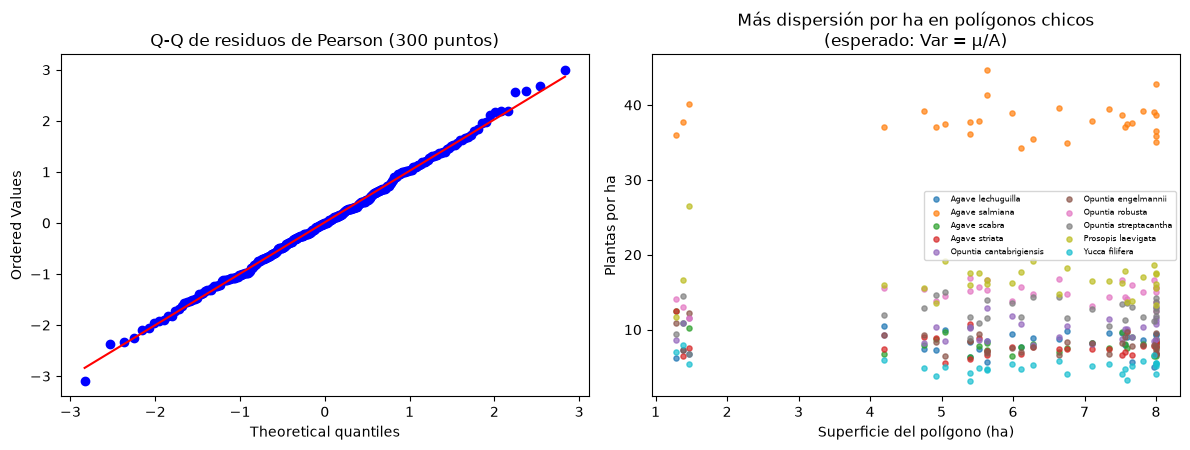

In [5]:
r = resid.values.ravel()
print('media:', r.mean().round(3), '| desv. est.:', r.std(ddof=1).round(3))
print('Shapiro-Wilk de los residuos: p =', round(stats.shapiro(r).pvalue, 4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
stats.probplot(r, dist='norm', plot=ax[0])
ax[0].set_title('Q-Q de residuos de Pearson (300 puntos)')
for s in dens_obs.index:
    ax[1].scatter(area.values, dens_obs.loc[s].values, s=14, alpha=.7, label=s)
ax[1].set_xlabel('Superficie del polígono (ha)'); ax[1].set_ylabel('Plantas por ha')
ax[1].set_title('Más dispersión por ha en polígonos chicos\n(esperado: Var = μ/A)')
ax[1].legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()

## 5. Comprobación Monte Carlo de la prueba (opcional)
La aproximación χ² es menos precisa con conteos bajos (p. ej. *Yucca*, ≈5 plantas/ha en polígonos chicos). Se simula el estadístico bajo $H_0$ con los mismos $\hat\lambda_{sj}$.

In [6]:
rng = np.random.default_rng(42)
B = 20000
sim = np.empty((B, len(conteos)))
for k in range(B):
    N = rng.poisson(lam.values)
    # reestimar μ en cada réplica, igual que con los datos reales
    mu_b = N.sum(axis=1) / area.sum()
    lam_b = np.outer(mu_b, area.values)
    sim[k] = ((N - lam_b)**2 / lam_b).sum(axis=1)

p_mc = pd.DataFrame({
    'chi2_obs': chi2.values,
    'p_sobredisp_MC': (sim >= chi2.values).mean(axis=0),
    'p_subdisp_MC': (sim <= chi2.values).mean(axis=0),
}, index=conteos.index).round(4)
p_mc

,chi2_obs,p_sobredisp_MC,p_subdisp_MC
especie,,,
Agave lechuguilla,42.0173,0.0562,0.9438
Agave salmiana,24.6297,0.6949,0.3051
Agave scabra,27.0719,0.5638,0.4362
Agave striata,29.9509,0.4123,0.5877
Opuntia cantabrigiensis,36.4307,0.1633,0.8367
Opuntia engelmannii,25.0893,0.6720,0.3280
Opuntia robusta,16.9613,0.9636,0.0364
Opuntia streptacantha,32.6771,0.2911,0.7089
Prosopis laevigata,39.1002,0.0986,0.9014


## 6. Composición por especie y total por ha
El total por ha es casi fijo (subdisperso respecto a Poisson) y la composición es homogénea entre polígonos, lo que sugiere un reparto multinomial de un total casi constante.

In [7]:
tot = conteos.sum(axis=0)
mu_tot = tot.sum() / area.sum()
lam_tot = mu_tot * area
chi2_tot = ((tot - lam_tot)**2 / lam_tot).sum()
print(f'Total por ha: μ̂ = {mu_tot:.2f} | χ² = {chi2_tot:.1f} (gl={J-1}) | '
      f'p subdispersión = {stats.chi2.cdf(chi2_tot, J-1):.4f}')

chi2_h, p_h, gl_h, _ = stats.chi2_contingency(conteos.values)
print(f'Homogeneidad de composición entre polígonos: χ² = {chi2_h:.1f}, gl = {gl_h}, p = {p_h:.3f}')

Total por ha: μ̂ = 128.79 | χ² = 11.9 (gl=29) | p subdispersión = 0.0021
Homogeneidad de composición entre polígonos: χ² = 286.7, gl = 261, p = 0.132
